# 01 — Comportamiento electoral presidencial 2024 por municipio

Este notebook explora los resultados de la elección presidencial de 2024 (cómputos distritales del INE) agregados a nivel municipal.

**Candidaturas:**
- **Sheinbaum** (PVEM–PT–MORENA)
- **Gálvez** (PAN–PRI–PRD)
- **Máynez** (MC)

Fuente: INE, Cómputos Distritales 2024; cartografía: INEGI (gaia); socioeconomía: CONAPO 2020.

In [1]:
import sys, os
sys.path.insert(0, os.path.join("..", "src"))
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

BASE = os.path.join("..")
PROCESADOS = os.path.join(BASE, "data", "processed")
FIGURAS = os.path.join(BASE, "figuras")
os.makedirs(FIGURAS, exist_ok=True)

df = pd.read_csv(os.path.join(PROCESADOS, "municipios_electoral_social.csv"),
                 dtype={"cvegeo": str})
gdf = gpd.read_file(os.path.join(PROCESADOS, "municipios_cartografia_simplificada.gpkg"))
gdf["cvegeo"] = gdf["cvegeo"].str.zfill(5)
gdf = gdf.merge(df, on="cvegeo", how="left")
print(f"{len(df)} municipios con datos, {len(gdf)} polígonos")
gdf.head(3)


2469 municipios con datos, 2478 polígonos


,cvegeo,nomgeo,geometry,cve_ent,nom_ent,cve_mun,nom_mun,pob_total,pct_analfabeta,pct_sin_basica,...,total_votos_candidaturas,total_votos,lista_nominal,n_casillas,pct_sheinbaum,pct_galvez,pct_maynez,pct_participacion,pct_mas_votado,ganador
0,01001,Aguascalientes,"MULTIPOLYGON (((-102.10732 22.07476, -102.1036...",1.0,Aguascalientes,1001.0,Aguascalientes,948990.0,1.644738,20.367220,...,431166.0,440900.0,732938.0,1269.0,41.828437,48.932894,9.238669,60.155156,48.932894,galvez
1,01008,San José de Gracia,"MULTIPOLYGON (((-102.45611 22.32323, -102.4501...",1.0,Aguascalientes,1008.0,San José de Gracia,9552.0,2.439773,28.419940,...,5638.0,5785.0,7778.0,14.0,41.025186,35.899255,23.075559,74.376446,41.025186,sheinbaum
2,01011,San Francisco de los Romo,"MULTIPOLYGON (((-102.15938 22.099, -102.14086 ...",1.0,Aguascalientes,1011.0,San Francisco de los Romo,61997.0,2.358762,28.466145,...,11355.0,11589.0,17010.0,26.0,69.194188,25.962131,4.843681,68.130511,69.194188,sheinbaum


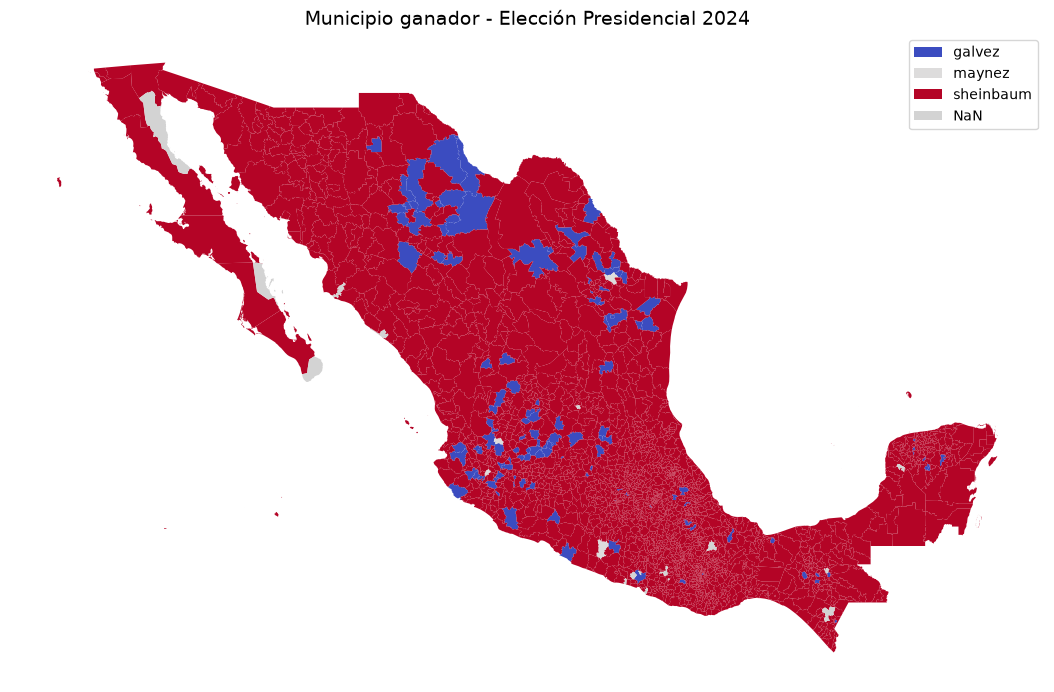

In [2]:
ax = gdf.plot(column="ganador", categorical=True, missing_kwds={"color": "lightgrey"},
              figsize=(11, 7), legend=True,
              cmap="coolwarm", edgecolor="none")
ax.set_title("Municipio ganador - Elección Presidencial 2024", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "mapa_ganador.png"), dpi=150, bbox_inches="tight")
plt.show()

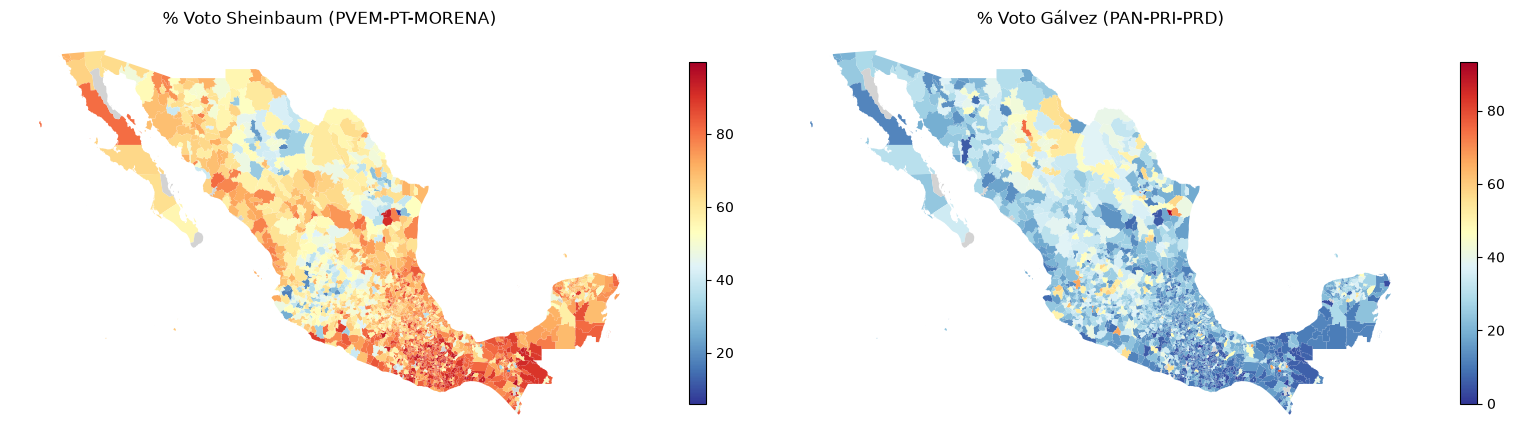

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, titulo in zip(axes, ["pct_sheinbaum", "pct_galvez"],
                           ["% Voto Sheinbaum (PVEM-PT-MORENA)", "% Voto Gálvez (PAN-PRI-PRD)"]):
    gdf.plot(column=col, ax=ax, legend=True, cmap="RdYlBu_r",
             legend_kwds={"shrink": 0.6}, missing_kwds={"color": "lightgrey"})
    ax.set_title(titulo, fontsize=12)
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "mapa_voto_candidaturas.png"), dpi=150, bbox_inches="tight")
plt.show()

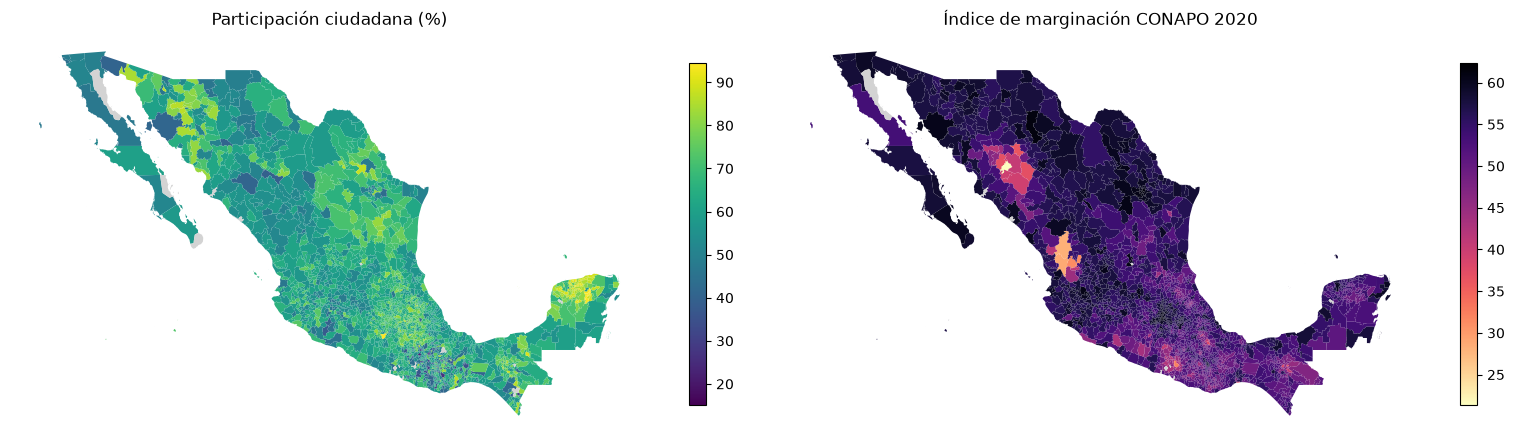

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, titulo, cmap in zip(axes, ["pct_participacion", "im_2020"],
                                 ["Participación ciudadana (%)", "Índice de marginación CONAPO 2020"],
                                 ["viridis", "magma_r"]):
    gdf.plot(column=col, ax=ax, legend=True, cmap=cmap,
             legend_kwds={"shrink": 0.6}, missing_kwds={"color": "lightgrey"})
    ax.set_title(titulo, fontsize=12)
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "mapa_participacion_marginacion.png"), dpi=150, bbox_inches="tight")
plt.show()

In [5]:
df_elec = df.dropna(subset=["pct_sheinbaum"])
print("Nacionales (agregado municipal ponderado por votos):")
for c in ["sheinbaum", "galvez", "maynez"]:
    print(f"  {c}: {100 * df_elec[c].sum() / df_elec['total_votos_candidaturas'].sum():.2f}%")
print(f"  participación: {100 * df_elec['total_votos'].sum() / df_elec['lista_nominal'].sum():.2f}%")
print()
print("Municipios más polarizados (mayor y menor voto a Sheinbaum):")
cols = ["nom_mun", "nom_ent", "pct_sheinbaum", "pct_galvez", "pct_maynez", "pct_participacion"]
display(df_elec.nlargest(5, "pct_sheinbaum")[cols])
display(df_elec.nsmallest(5, "pct_sheinbaum")[cols])

Nacionales (agregado municipal ponderado por votos):
  sheinbaum: 61.28%
  galvez: 28.10%
  maynez: 10.62%
  participación: 61.03%

Municipios más polarizados (mayor y menor voto a Sheinbaum):


,nom_mun,nom_ent,pct_sheinbaum,pct_galvez,pct_maynez,pct_participacion
139,Nicolás Ruíz,Chiapas,99.812171,0.075131,0.112697,80.648065
1449,Santa María Xadani,Oaxaca,98.878924,0.672646,0.448430,68.292683
1513,Santo Domingo Ingenio,Oaxaca,97.715736,2.030457,0.253807,63.057325
1119,San Antonio Tepetlapa,Oaxaca,97.491039,1.792115,0.716846,55.684008
198,San Andrés Duraznal,Chiapas,97.420021,1.496388,1.083591,65.025126


,nom_mun,nom_ent,pct_sheinbaum,pct_galvez,pct_maynez,pct_participacion
2025,San Nicolás,Tamaulipas,6.047198,93.362832,0.589971,74.197002
650,Valle de Juárez,Jalisco,15.176076,70.178871,14.645053,52.810439
614,San Martín de Bolaños,Jalisco,16.395553,59.707431,23.897016,63.508772
191,Zinacantán,Chiapas,17.421568,79.320085,3.258348,88.323511
596,Mascota,Jalisco,17.669753,53.935185,28.395062,64.620590
